# Stock Price Prediction Project
Dataset Link-https://drive.google.com/file/d/1tHJXu_SVJx1pb7Od4f8TokqDGwk3Or7J/view?usp=sharing

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn
!pip install -q flask pyngrok

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error, r2_score


In [ ]:
# Upload World-Stock-Prices-Dataset.csv to Google Colab before running this cell
df = pd.read_csv("/content/World-Stock-Prices-Dataset.csv")

df.head(10)

,Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits,Capital Gains
0,2025-07-03 00:00:00-04:00,6.630000,6.740000,6.615000,6.640000,4209664.0,peloton,PTON,fitness,usa,0.0,0.0,NaN
1,2025-07-03 00:00:00-04:00,106.750000,108.370003,106.330101,107.339996,560190.0,crocs,CROX,footwear,usa,0.0,0.0,NaN
2,2025-07-03 00:00:00-04:00,122.629997,123.050003,121.550003,121.930000,36600.0,adidas,ADDYY,apparel,germany,0.0,0.0,NaN
3,2025-07-03 00:00:00-04:00,221.705002,224.009995,221.360001,223.410004,29295154.0,amazon,AMZN,e-commerce,usa,0.0,0.0,NaN
4,2025-07-03 00:00:00-04:00,212.145004,214.649994,211.810104,213.550003,34697317.0,apple,AAPL,technology,usa,0.0,0.0,NaN
5,2025-07-03 00:00:00-04:00,76.264999,77.029999,75.580002,76.389999,11545304.0,nike,NKE,apparel,usa,0.0,0.0,NaN
6,2025-07-03 00:00:00-04:00,105.949997,105.969902,104.055000,104.059998,3535290.0,target,TGT,retail,usa,0.0,0.0,NaN
7,2025-07-03 00:00:00-04:00,178.695007,179.669998,177.059998,179.529999,21563145.0,google,GOOGL,technology,usa,0.0,0.0,NaN
8,2025-07-03 00:00:00-04:00,713.000000,725.549988,704.549988,725.049988,1071771.0,spotify,SPOT,music,usa,0.0,0.0,NaN
9,2025-07-03 00:00:00-04:00,77.599998,79.824997,77.410004,78.580002,2882442.0,zoom video communications,ZM,technology,usa,0.0,0.0,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114730 entries, 0 to 114729
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           114730 non-null  object 
 1   Open           114730 non-null  float64
 2   High           114729 non-null  float64
 3   Low            114729 non-null  float64
 4   Close          114729 non-null  float64
 5   Volume         114729 non-null  float64
 6   Brand_Name     114729 non-null  object 
 7   Ticker         114729 non-null  object 
 8   Industry_Tag   114729 non-null  object 
 9   Country        114729 non-null  object 
 10  Dividends      114729 non-null  float64
 11  Stock Splits   114729 non-null  float64
 12  Capital Gains  2 non-null       float64
dtypes: float64(8), object(5)
memory usage: 11.4+ MB


In [ ]:
df.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
count,114730.000000,114729.000000,114729.000000,114729.000000,1.147290e+05,114729.000000,114729.000000,2.0
mean,146.599119,148.366757,144.786826,146.617194,1.429895e+07,0.005393,0.001239,0.0
std,205.262993,207.454003,202.937622,205.249215,3.661379e+07,0.096347,0.179395,0.0
min,0.000000,0.000000,0.000000,1.890000,0.000000e+00,0.000000,0.000000,0.0
25%,46.301620,46.852789,45.791466,46.290596,1.469700e+06,0.000000,0.000000,0.0
50%,98.055435,99.216208,96.939298,98.027382,4.128200e+06,0.000000,0.000000,0.0
75%,170.633008,172.583392,168.809998,170.788666,1.075830e+07,0.000000,0.000000,0.0
max,3445.580078,3463.070068,3370.000000,3427.610107,1.142269e+09,15.000000,50.000000,0.0


In [ ]:
df.isnull().sum()

,0
Date,0
Open,0
High,1
Low,1
Close,1
Volume,1
Brand_Name,1
Ticker,1
Industry_Tag,1
Country,1


In [ ]:
print("Size -->", df.shape)

# Print the number of rows (axis 0)
print("Rows  -->", df.shape[0])

# Print the number of columns (axis 1)
print("Columns -->", df.shape[1])

Size --> (114730, 13)
Rows  --> 114730
Columns --> 13


In [ ]:
print(df['Brand_Name'].count())

114729


In [ ]:
import pandas as pd
brand_counts=df['Brand_Name'].dropna().unique()
clean_brand = [str(brand) for brand  in brand_counts]
print(sorted(clean_brand))

['3m', 'adidas', 'adobe', 'airbnb', 'amazon', 'amd', 'american eagle outfitters', 'american express', 'apple', 'block', 'bmw group', 'chipotle', 'cisco', 'coinbase', 'colgate palmolive', 'costco', 'crocs', 'delta air lines', 'fedex', 'foot locker', 'google', 'hershey company', 'hilton', 'honda', 'johnson & johnson', 'jpmorgan chase & co', 'logitech', 'lvmh', 'marriott', 'mastercard', "mcdonald's", 'microsoft', 'netflix', 'nike', 'nintendo', 'nordstrom', 'nvidia', 'peloton', 'philips', 'pinterest', 'porsche', 'procter & gamble', 'puma', 'roblox', 'salesforce / slack', 'shopify', 'southwest airlines', 'spotify', 'starbucks', 'target', 'tesla', 'the coca-cola company', 'the home depot', 'the walt disney company', 'toyota', 'twitter', 'uber', 'ubisoft', 'unilever', 'visa', 'zoom video communications', 'zoominfo']


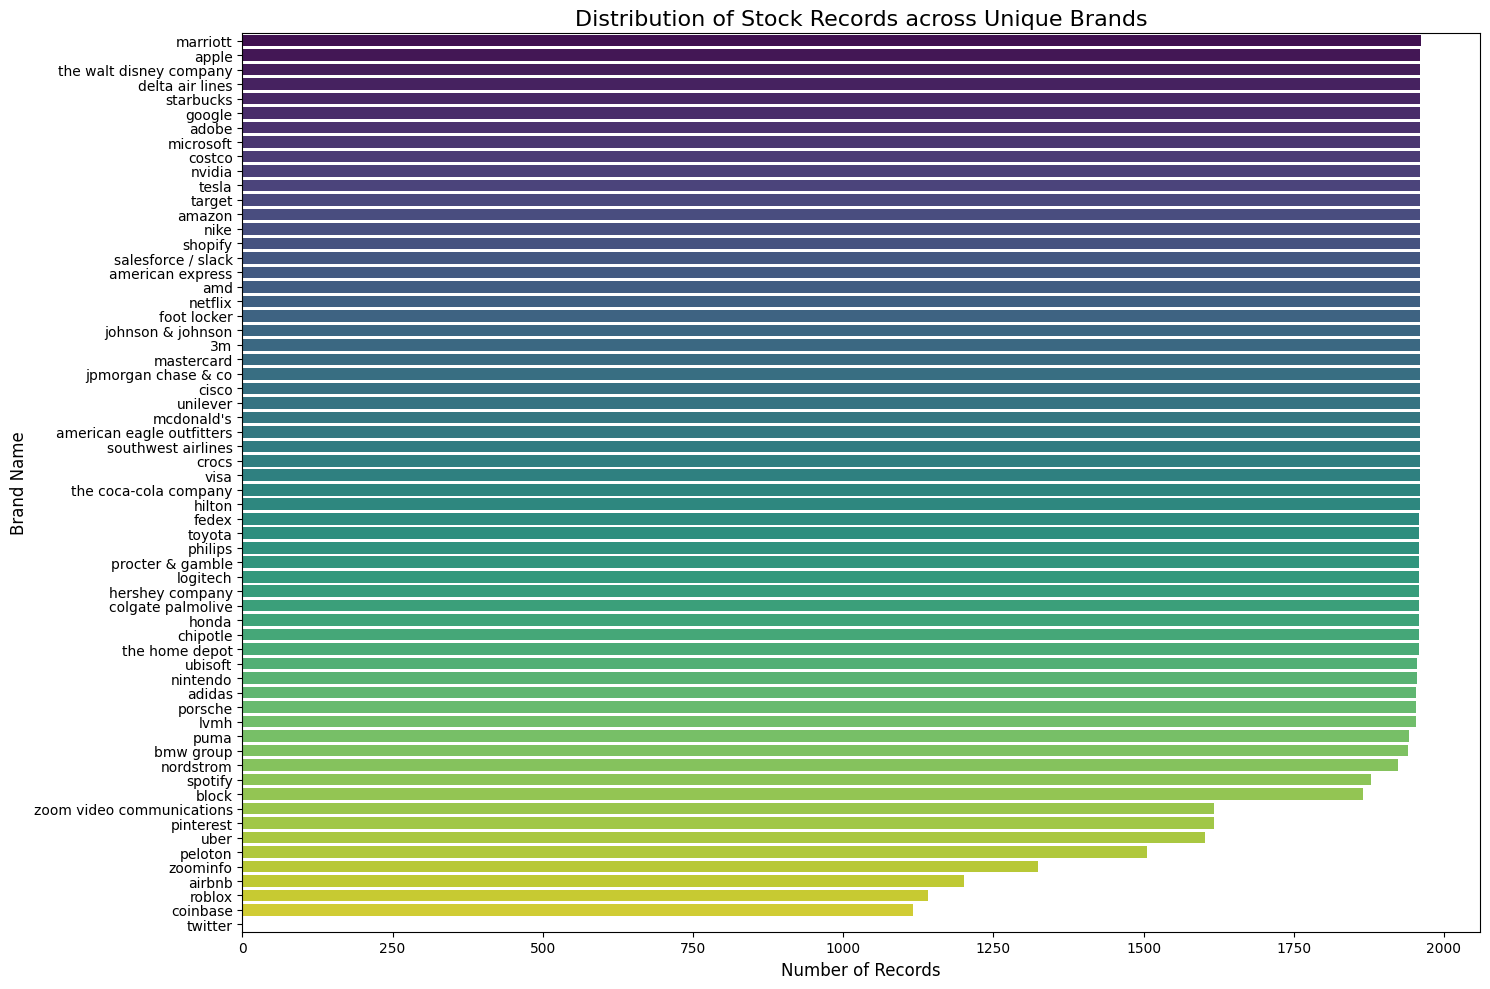

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each unique brand
brand_counts = df['Brand_Name'].value_counts()

# Plot the brand distribution
plt.figure(figsize=(15, 10))
sns.barplot(x=brand_counts.values, y=brand_counts.index, palette='viridis', hue=brand_counts.index, legend=False)
plt.title('Distribution of Stock Records across Unique Brands', fontsize=16)
plt.xlabel('Number of Records', fontsize=12)
plt.ylabel('Brand Name', fontsize=12)
plt.tight_layout()
plt.show()

### 1.Exploratory Data Analysis (EDA)


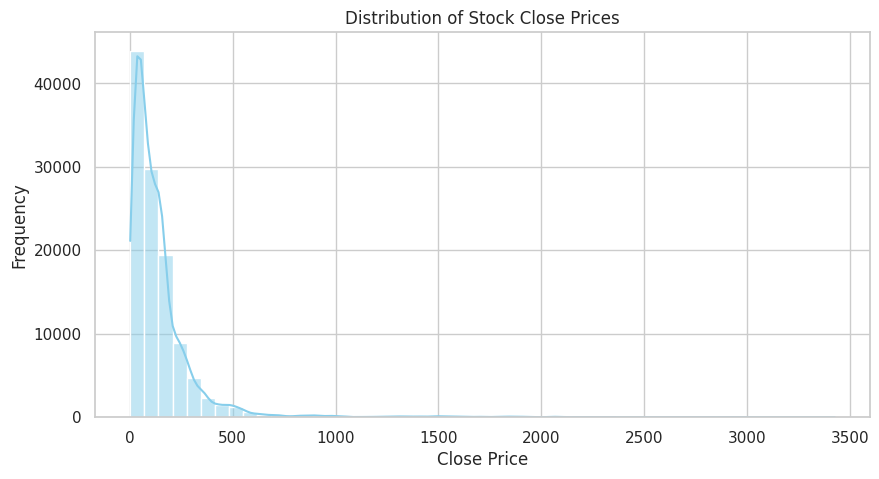

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Distribution of Close Prices
plt.figure(figsize=(10, 5))
sns.histplot(df['Close'], bins=50, kde=True, color='skyblue')
plt.title('Distribution of Stock Close Prices')
plt.xlabel('Close Price')
plt.ylabel('Frequency')
plt.show()

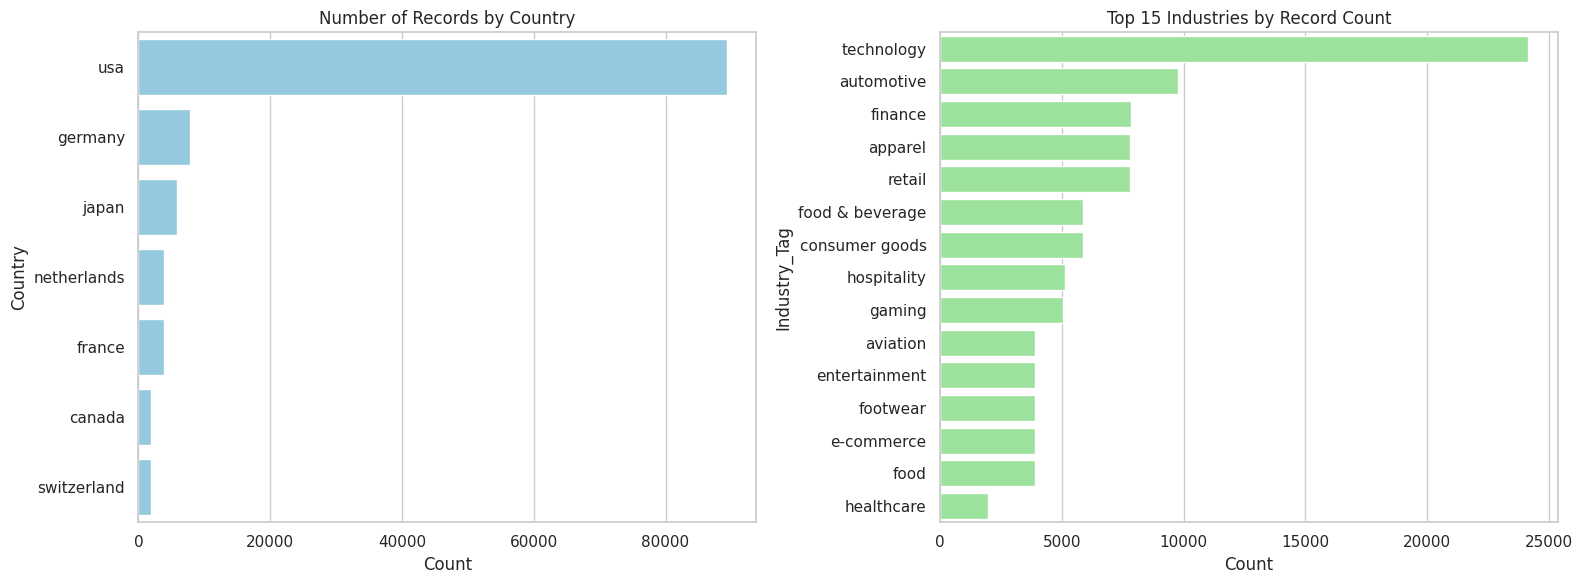

In [ ]:
# 2. Stock Records Count by Country and Industry
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=df, y='Country', order=df['Country'].value_counts().index, ax=axes[0], color='skyblue')
axes[0].set_title('Number of Records by Country')
axes[0].set_xlabel('Count')

sns.countplot(data=df, y='Industry_Tag', order=df['Industry_Tag'].value_counts().index[:15], ax=axes[1], color='lightgreen')
axes[1].set_title('Top 15 Industries by Record Count')
axes[1].set_xlabel('Count')

plt.tight_layout()
plt.show()

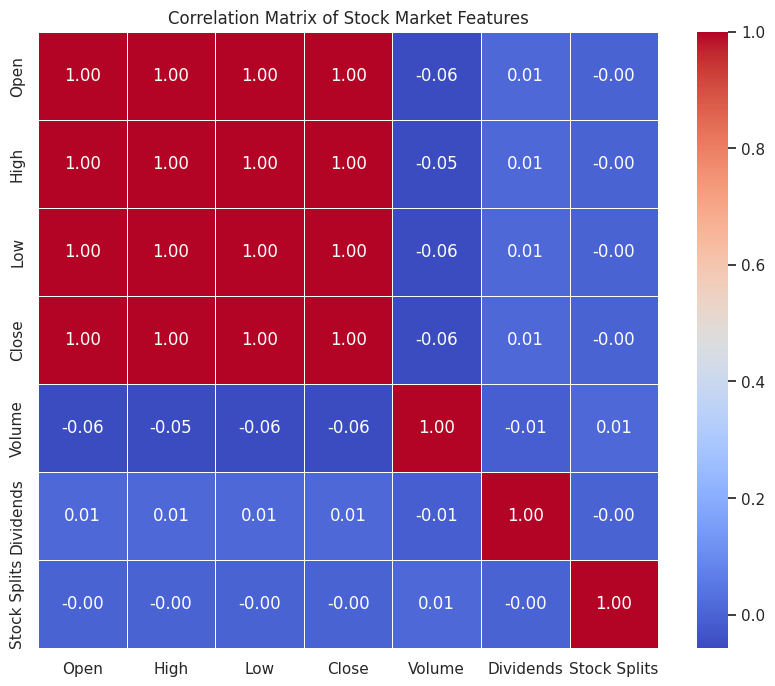

In [ ]:
# 3. Correlation Heatmap of Numerical Features
plt.figure(figsize=(10, 8))
numerical_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Stock Market Features')
plt.show()

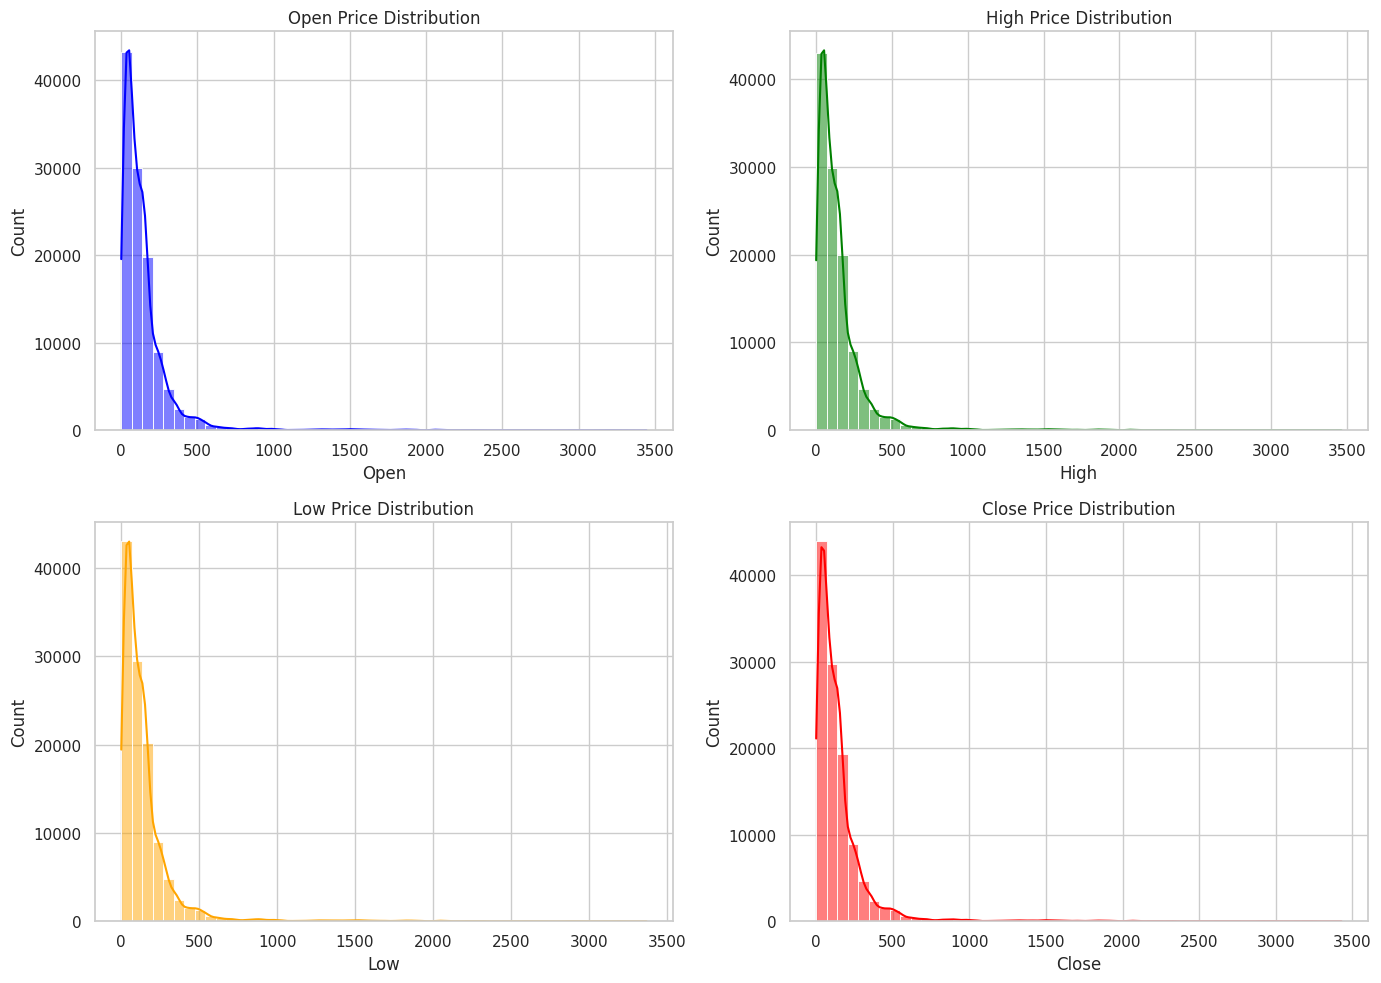

In [ ]:
# 4. Distribution comparison of Open, High, Low, and Close Prices
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['Open'].dropna(), bins=50, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Open Price Distribution')

sns.histplot(df['High'].dropna(), bins=50, kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title('High Price Distribution')

sns.histplot(df['Low'].dropna(), bins=50, kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Low Price Distribution')

sns.histplot(df['Close'].dropna(), bins=50, kde=True, ax=axes[1, 1], color='red')
axes[1, 1].set_title('Close Price Distribution')

plt.tight_layout()
plt.show()

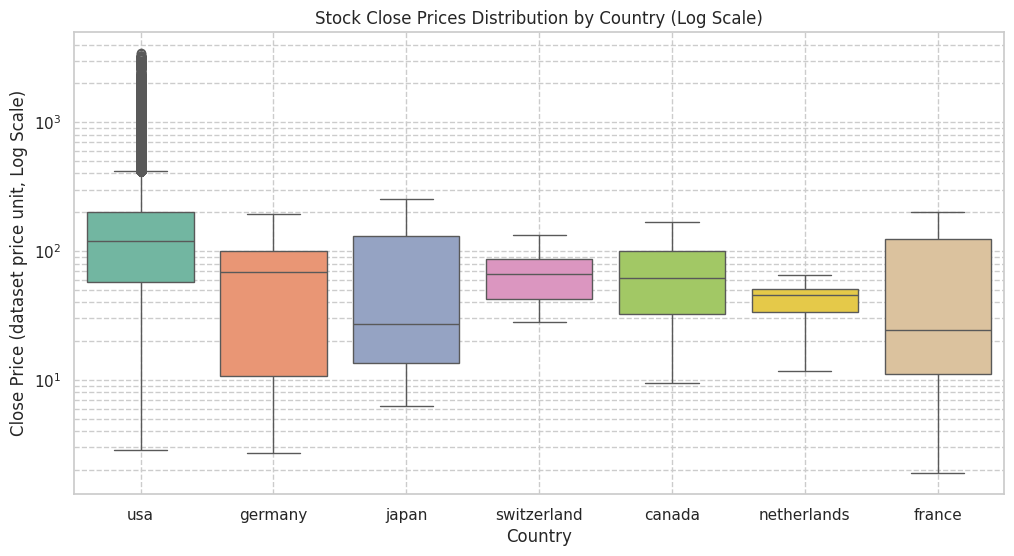

In [ ]:
# 5. Box Plot of Stock Close Prices by Country (Log Scale for better comparison)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.dropna(subset=['Country', 'Close']), x='Country', y='Close', palette='Set2', hue='Country', legend=False)
plt.yscale('log')
plt.title('Stock Close Prices Distribution by Country (Log Scale)')
plt.xlabel('Country')
plt.ylabel('Close Price (dataset price unit, Log Scale)')
plt.grid(True, which="both", ls="--")
plt.show()

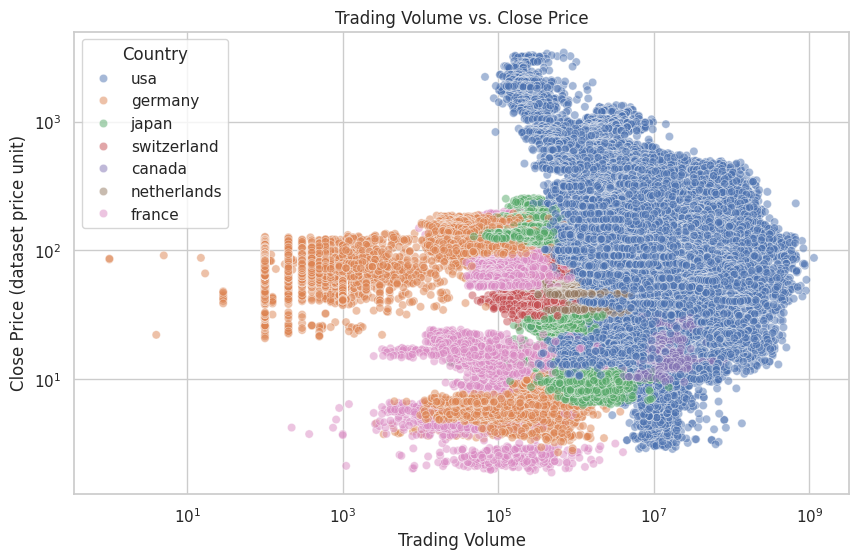

In [ ]:
# 6. Volume vs. Close Price Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Volume', y='Close', alpha=0.5, hue='Country')
plt.title('Trading Volume vs. Close Price')
plt.xlabel('Trading Volume')
plt.ylabel('Close Price (dataset price unit)')
plt.xscale('log')
plt.yscale('log')
plt.grid(True)
plt.show()

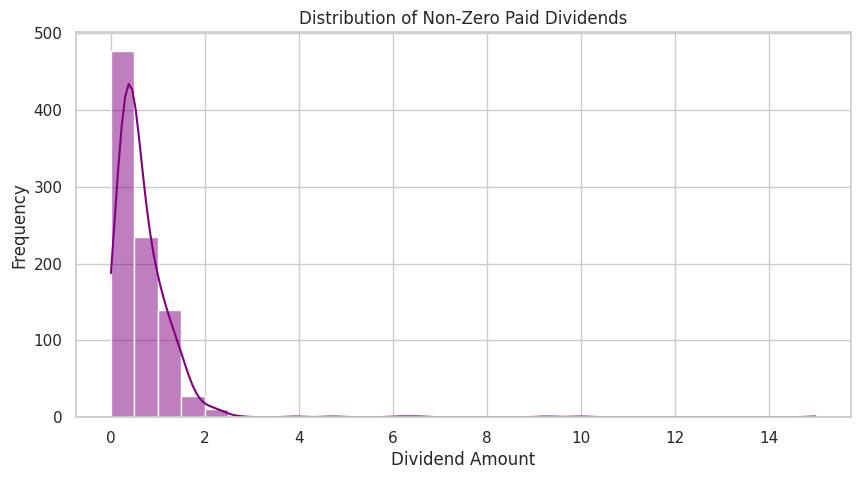

In [ ]:
# 7. Distribution of Non-Zero Dividends
plt.figure(figsize=(10, 5))
dividends_filtered = df[df['Dividends'] > 0]['Dividends']
sns.histplot(dividends_filtered, bins=30, kde=True, color='purple')
plt.title('Distribution of Non-Zero Paid Dividends')
plt.xlabel('Dividend Amount')
plt.ylabel('Frequency')
plt.show()

<Figure size 1000x1000 with 0 Axes>

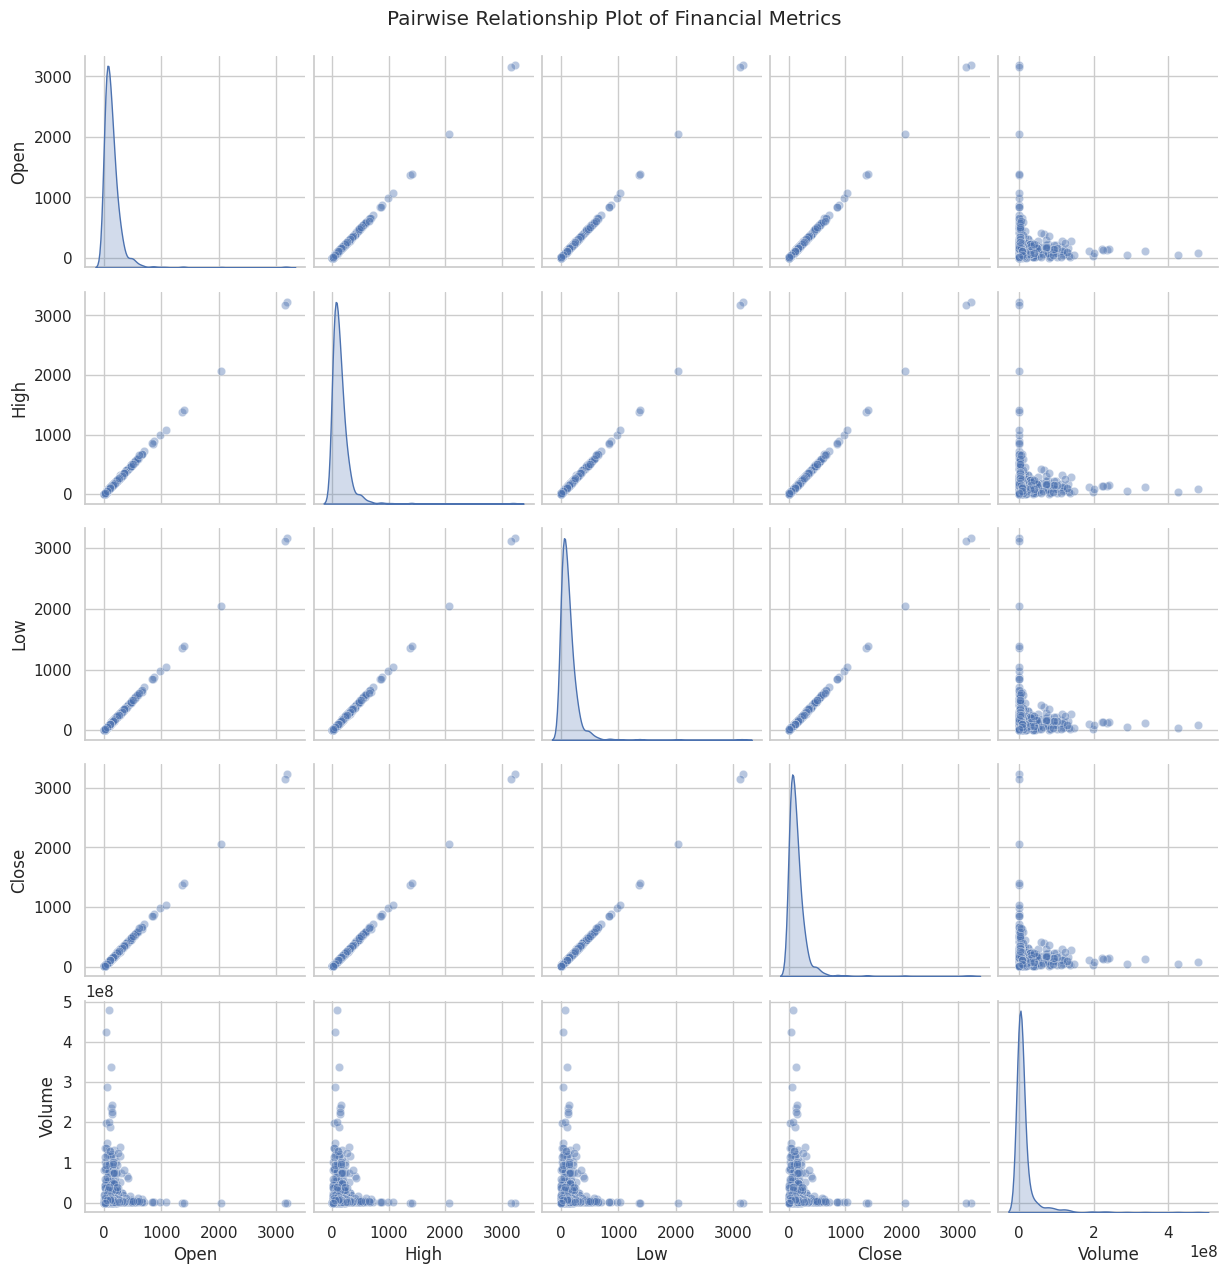

In [ ]:
# 8. Pairplot of Primary Financial Metrics (sampled to speed up execution)
plt.figure(figsize=(10, 10))
sample_df = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna().sample(n=1000, random_state=42)
sns.pairplot(sample_df, diag_kind='kde', plot_kws={'alpha': 0.4})
plt.suptitle('Pairwise Relationship Plot of Financial Metrics', y=1.02)
plt.show()

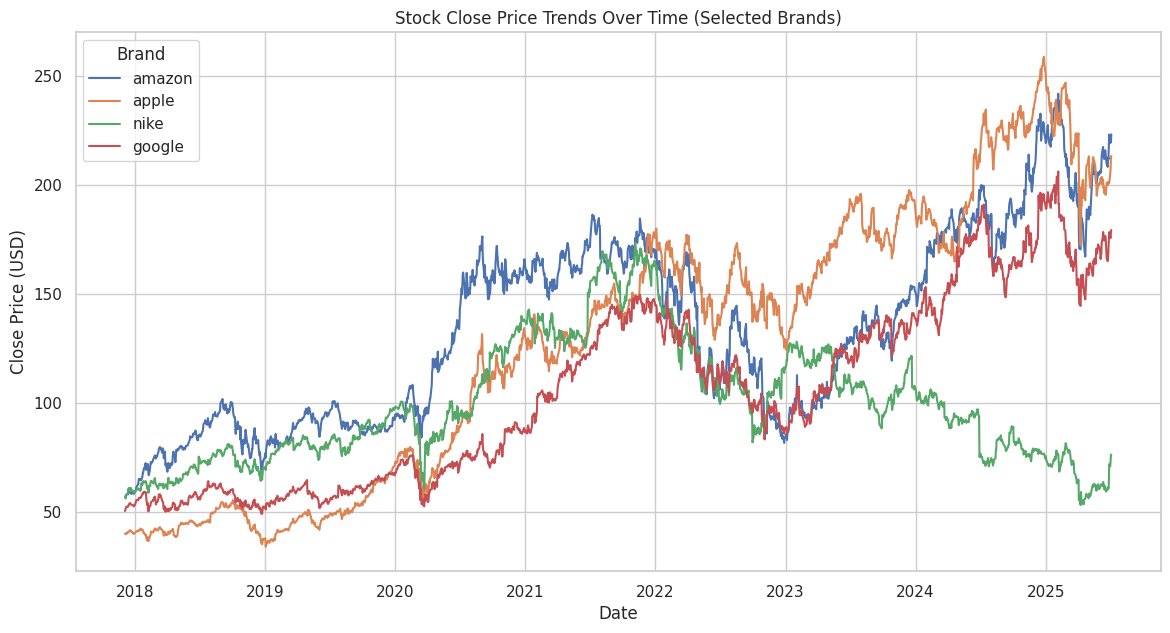

In [ ]:
# 9. Temporal Trend analysis for a few selected Brands
# Convert Date to datetime format temporarily for plotting
df_temp = df.copy()
df_temp['Date'] = pd.to_datetime(df_temp['Date'], utc=True)

top_brands = ['apple', 'google', 'amazon', 'nike']
df_subset = df_temp[df_temp['Brand_Name'].isin(top_brands)]

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_subset, x='Date', y='Close', hue='Brand_Name')
plt.title('Stock Close Price Trends Over Time (Selected Brands)')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend(title='Brand')
plt.grid(True)
plt.show()

### 2. Data Cleaning

We remove duplicate company-date records, remove the mostly empty `Capital Gains` column, and keep valid stock-price records.

In [ ]:
# Remove the column that is almost completely empty
df_reg = df.drop(columns=['Capital Gains'])

# Convert Date into datetime format
df_reg['Date'] = pd.to_datetime(df_reg['Date'], utc=True)

# Remove duplicate records for the same stock and date
df_reg = df_reg.drop_duplicates(subset=['Ticker', 'Date'])

# Keep rows with the information needed for prediction
df_reg = df_reg.dropna(subset=[
    'Brand_Name', 'Ticker', 'Industry_Tag', 'Country',
    'Open', 'High', 'Low', 'Close', 'Volume'
])

# Keep valid OHLC prices
df_reg = df_reg[
    (df_reg['Open'] > 0) &
    (df_reg['High'] > 0) &
    (df_reg['Low'] > 0) &
    (df_reg['Close'] > 0) &
    (df_reg['Volume'] >= 0) &
    (df_reg['High'] >= df_reg[['Open', 'Low', 'Close']].max(axis=1)) &
    (df_reg['Low'] <= df_reg[['Open', 'High', 'Close']].min(axis=1))
].copy()

# Missing dividend/split values mean no dividend or split on that date
df_reg[['Dividends', 'Stock Splits']] = df_reg[['Dividends', 'Stock Splits']].fillna(0)

# Add simple date features
df_reg['Year'] = df_reg['Date'].dt.year
df_reg['Month'] = df_reg['Date'].dt.month
df_reg['Day'] = df_reg['Date'].dt.day
df_reg['DayOfWeek'] = df_reg['Date'].dt.dayofweek

df_reg = df_reg.sort_values(['Ticker', 'Date']).reset_index(drop=True)

print("Shape after cleaning:", df_reg.shape)
print("Number of companies:", df_reg['Ticker'].nunique())
df_reg.head()

Shape after cleaning: (110919, 16)
Number of companies: 61


,Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits,Year,Month,Day,DayOfWeek
0,2017-12-04 05:00:00+00:00,40.828597,40.861737,40.153961,40.194202,130169600.0,apple,AAPL,technology,usa,0.0,0.0,2017,12,4,0
1,2017-12-05 05:00:00+00:00,40.019035,40.601355,39.862802,40.156330,109400800.0,apple,AAPL,technology,usa,0.0,0.0,2017,12,5,1
2,2017-12-06 05:00:00+00:00,39.649764,40.288894,39.403582,40.007202,114240000.0,apple,AAPL,technology,usa,0.0,0.0,2017,12,6,2
3,2017-12-07 05:00:00+00:00,40.011944,40.345713,39.983539,40.080593,102693200.0,apple,AAPL,technology,usa,0.0,0.0,2017,12,7,3
4,2017-12-08 05:00:00+00:00,40.357542,40.478265,39.962228,40.092419,93420800.0,apple,AAPL,technology,usa,0.0,0.0,2017,12,8,4


### 3. Preparing Data for Next Trading Day Prediction

The target is changed from today's `Close` to the **next available trading session's Close for the same ticker**. The model predicts the percentage change, then converts it into a closing-price estimate.

In [ ]:
# Sort each company's records by date
df_future = df_reg.sort_values(['Ticker', 'Date']).copy()

# Get the next trading record for the same stock
df_future['Next_Close'] = df_future.groupby('Ticker')['Close'].shift(-1)
df_future['Next_Date'] = df_future.groupby('Ticker')['Date'].shift(-1)

# Calculate the percentage change to the next closing price
df_future['Target_Return'] = (df_future['Next_Close'] - df_future['Close']) / df_future['Close']

df_future = df_future.dropna(subset=['Next_Close', 'Next_Date', 'Target_Return']).copy()

# Include company name, ticker, industry and country as model features
category_columns = ['Brand_Name', 'Ticker', 'Industry_Tag', 'Country']
model_data = df_future[[
    'Date', 'Next_Date', 'Next_Close', 'Target_Return',
    'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits',
    'Year', 'Month', 'Day', 'DayOfWeek',
    'Brand_Name', 'Ticker', 'Industry_Tag', 'Country'
]].copy()

# Convert company details into numeric columns
model_data = pd.get_dummies(model_data, columns=category_columns, drop_first=True)

# Select the input columns (do not include dates or the answer)
feature_columns = [
    col for col in model_data.columns
    if col not in ['Date', 'Next_Date', 'Next_Close', 'Target_Return']
]

# Split by date so that older records train the model and newer records test it
split_date = model_data['Date'].quantile(0.80)
train_data = model_data[
    (model_data['Date'] < split_date) &
    (model_data['Next_Date'] < split_date)
]
test_data = model_data[
    (model_data['Date'] >= split_date) &
    (model_data['Next_Date'] >= split_date)
]

X_train = train_data[feature_columns]
y_train = train_data['Target_Return']
X_test = test_data[feature_columns]
y_test = test_data['Target_Return']

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of input features:", len(feature_columns))

Training records: 88567
Testing records: 22230
Number of input features: 159


### 4. Training the Regression Model

We use a Random Forest Regressor to learn the relationship between historical stock information and the next-session percentage price change.

,MAE,MSE,RMSE,MAPE (%),R2 Score
Previous Close Baseline,2.597308,37.394661,6.115117,1.587076,0.999442
Lasso Regression,2.603396,37.579495,6.130212,1.593376,0.999439
Ridge Regression,2.704763,48.037549,6.930913,1.604431,0.999283
Linear Regression,2.790638,58.606755,7.655505,1.611728,0.999126
Random Forest,2.608136,37.643933,6.135465,1.643498,0.999439
Gradient Boosting,2.920228,45.342653,6.733695,1.713753,0.999324
Decision Tree,2.713809,40.286642,6.347176,1.726496,0.999399
K-Nearest Neighbours,3.070943,51.692983,7.189783,1.836241,0.999229


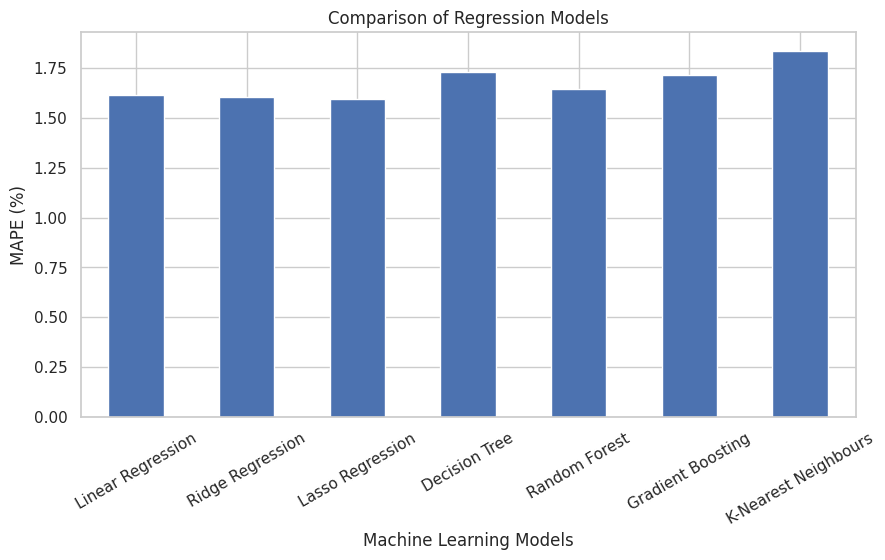

Selected Model: Lasso Regression
Final model training completed!


In [ ]:

# Use a smaller common sample to compare models faster
X_train_small = X_train.sample(
    n=min(20000, len(X_train)), random_state=42
)
y_train_small = y_train.loc[X_train_small.index]

X_test_small = X_test.sample(
    n=min(3000, len(X_test)), random_state=42
)

test_small = test_data.loc[X_test_small.index]

actual_close = test_small['Next_Close'].to_numpy()
today_close = test_small['Close'].to_numpy()

# All seven models
models = {
    'Linear Regression': make_pipeline(
        StandardScaler(), LinearRegression()
    ),

    'Ridge Regression': make_pipeline(
        StandardScaler(), Ridge(alpha=1.0)
    ),

    'Lasso Regression': make_pipeline(
        StandardScaler(), Lasso(alpha=0.0001, max_iter=5000)
    ),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=10, random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=20, max_depth=8,
        random_state=42, n_jobs=2
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=50, max_depth=3,
        random_state=42
    ),

    'K-Nearest Neighbours': make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
    )
}

# Train and compare models
results = {}

for name, regressor in models.items():

    regressor.fit(X_train_small, y_train_small)

    predicted_return = regressor.predict(X_test_small)

    predicted_price = today_close * (1 + predicted_return)

    results[name] = {
        'MAE': mean_absolute_error(actual_close, predicted_price),
        'MSE': mean_squared_error(actual_close, predicted_price),
        'RMSE': np.sqrt(mean_squared_error(actual_close, predicted_price)),
        'MAPE (%)': mean_absolute_percentage_error(
            actual_close, predicted_price
        ) * 100,
        'R2 Score': r2_score(actual_close, predicted_price)
    }

# Add a simple previous-close baseline
results['Previous Close Baseline'] = {
    'MAE': mean_absolute_error(actual_close, today_close),
    'MSE': mean_squared_error(actual_close, today_close),
    'RMSE': np.sqrt(mean_squared_error(actual_close, today_close)),
    'MAPE (%)': mean_absolute_percentage_error(
        actual_close, today_close
    ) * 100,
    'R2 Score': r2_score(actual_close, today_close)
}

# Display comparison table
df_compare = pd.DataFrame(results).T
display(df_compare.sort_values('MAPE (%)'))

# Plot model comparison
df_compare.drop(
    index='Previous Close Baseline'
)['MAPE (%)'].plot(kind='bar', figsize=(10, 5))

plt.title('Comparison of Regression Models')
plt.ylabel('MAPE (%)')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=30)
plt.show()

# Select the best practical model (KNN is comparison-only
# because it is expensive on the full dataset)
best_model_name = df_compare.drop(
    index=['K-Nearest Neighbours', 'Previous Close Baseline']
)['MAPE (%)'].idxmin()

# Train selected model using the complete training data
model = models[best_model_name]
model.fit(X_train, y_train)

print("Selected Model:", best_model_name)
print("Final model training completed!")


### 5. Model Evaluation

The predicted percentage change is converted back into a closing-price estimate. We compare the estimate with the actual next-session closing price.

Mean Absolute Error (MAE): 2.6720
Mean Squared Error (MSE): 480.0049
Root Mean Squared Error (RMSE): 21.9090
R-squared (R2) Score: 0.9930
Baseline MAE: 2.6713


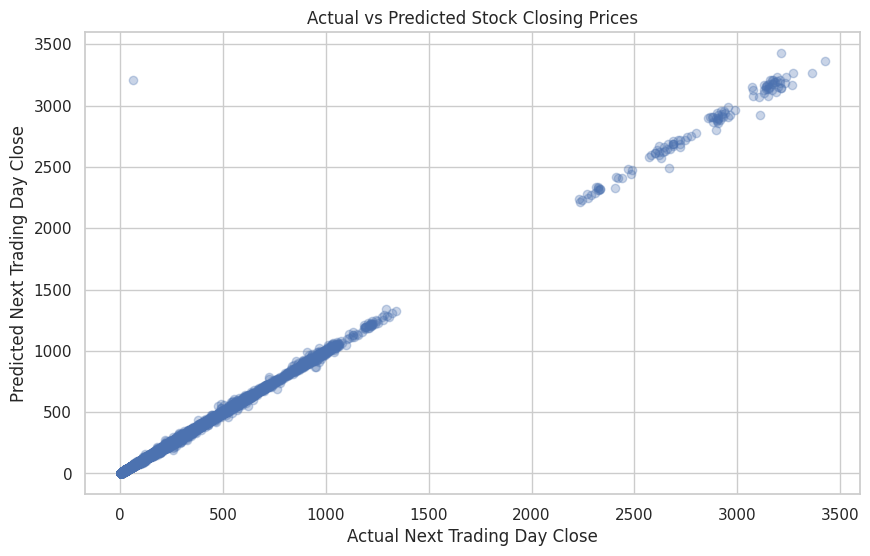

In [ ]:
# Predict the next-session percentage change
predicted_return = model.predict(X_test)

# Convert predicted returns into closing prices
predicted_close = test_data['Close'].to_numpy() * (1 + predicted_return)
actual_close = test_data['Next_Close'].to_numpy()

mae = mean_absolute_error(actual_close, predicted_close)
mse = mean_squared_error(actual_close, predicted_close)
rmse = np.sqrt(mse)
r2 = r2_score(actual_close, predicted_close)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")

# Compare the model with a simple prediction: next close = current close
baseline_close = test_data['Close'].to_numpy()
print("Baseline MAE:", round(mean_absolute_error(actual_close, baseline_close), 4))

# Plot actual versus predicted prices
plt.figure(figsize=(10, 6))
plt.scatter(actual_close, predicted_close, alpha=0.3)
plt.xlabel('Actual Next Trading Day Close')
plt.ylabel('Predicted Next Trading Day Close')
plt.title('Actual vs Predicted Stock Closing Prices')
plt.grid(True)
plt.show()

### 6. Prediction Example for a Company

This example selects one record from the test data and displays the predicted and actual next-session closing price.

In [ ]:
# Select one example from the test data
i = np.random.randint(0, len(X_test))

selected_row = df_future.loc[test_data.index[i]]
today_close = selected_row['Close']
actual_tomorrow_close = selected_row['Next_Close']
predicted_tomorrow_close = today_close * (1 + predicted_return[i])

print("Brand Name:", selected_row['Brand_Name'])
print("Ticker:", selected_row['Ticker'])
print("Today's Close Price:", round(today_close, 4))
print("Predicted Next Trading Day Close:", round(predicted_tomorrow_close, 4))
print("Actual Next Trading Day Close:", round(actual_tomorrow_close, 4))
print("Prediction Error:", round(abs(predicted_tomorrow_close - actual_tomorrow_close), 4))

Brand Name: procter & gamble
Ticker: PG
Today's Close Price: 175.59
Predicted Next Trading Day Close: 175.5544
Actual Next Trading Day Close: 176.06
Prediction Error: 0.5056


### 7. Predicting for a Selected Stock Using New Values


In [ ]:
0# Use the trained model to predict a new stock record

def predict_stock_price(ticker, date, open_price, high_price, low_price,
                        close_price, volume, dividends=0, stock_splits=0):
    company = df_reg[df_reg['Ticker'].str.upper() == ticker.upper()]

    if company.empty:
        raise ValueError("Ticker not found in the dataset.")

    company = company.iloc[-1]
    date = pd.to_datetime(date, utc=True)

    new_data = pd.DataFrame([{
        'Open': open_price,
        'High': high_price,
        'Low': low_price,
        'Close': close_price,
        'Volume': volume,
        'Dividends': dividends,
        'Stock Splits': stock_splits,
        'Year': date.year,
        'Month': date.month,
        'Day': date.day,
        'DayOfWeek': date.dayofweek,
        'Brand_Name': company['Brand_Name'],
        'Ticker': company['Ticker'],
        'Industry_Tag': company['Industry_Tag'],
        'Country': company['Country']
    }])

    # Use the full categories from training so the input columns match
    for column in category_columns:
        new_data[column] = pd.Categorical(
            new_data[column], categories=sorted(df_future[column].dropna().unique())
        )

    new_data = pd.get_dummies(new_data, columns=category_columns, drop_first=True)
    new_data = new_data.reindex(columns=feature_columns, fill_value=0)

    next_return = model.predict(new_data)[0]
    return close_price * (1 + next_return)


# # Example: enter the latest values for the company you want to predict
# ticker = input("Enter stock ticker (example: AAPL): ").strip().upper()
# date = input("Enter latest trading date (YYYY-MM-DD): ")
# open_price = float(input("Open price: "))
# high_price = float(input("High price: "))
# low_price = float(input("Low price: "))
# close_price = float(input("Close price: "))
# volume = float(input("Trading volume: "))

# dividends = float(input("Dividends (enter 0 if none): ") or 0)
# stock_splits = float(input("Stock splits (enter 0 if none): ") or 0)

# predicted_price = predict_stock_price(
#     ticker, date, open_price, high_price, low_price,
#     close_price, volume, dividends, stock_splits
# )

# print("Predicted Next Trading Day Closing Price:", round(predicted_price, 4))

### 8. Flask Connection for the HTML Page

 It provides three simple endpoints: `/metadata`, `/predict` and `/get_eda`.

In [ ]:
!pip install -q flask flask-cors pyngrok

In [ ]:
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok
import getpass
import io
import base64

app = Flask(__name__)
CORS(app)


@app.route('/metadata')
def metadata():
    companies = df_reg[['Brand_Name', 'Ticker', 'Industry_Tag', 'Country']].drop_duplicates()
    return jsonify({
        'status': 'success',
        'companies': companies.to_dict('records')
    })


@app.route('/predict', methods=['POST'])
def predict():
    try:
        data = request.get_json()
        price = predict_stock_price(
            data['ticker'], data['date'],
            float(data['open']), float(data['high']),
            float(data['low']), float(data['close']),
            float(data['volume']),
            float(data.get('dividends', 0)),
            float(data.get('stock_splits', 0))
        )
        return jsonify({'status': 'success', 'predicted_close': round(price, 4)})
    except Exception as e:
        return jsonify({'status': 'error', 'message': str(e)}), 400


def make_chart(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight')
    plt.close(fig)
    return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode()




@app.route('/get_eda')
def get_eda():
    charts = {}

    # 1. Brand Distribution
    fig, ax = plt.subplots(figsize=(12, 10))
    df['Brand_Name'].value_counts().sort_values().plot(kind='barh', ax=ax)
    ax.set_title('Stock Records by Brand')
    charts['brand_distribution'] = make_chart(fig)

    # 2. Close Price Distribution
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(df['Close'], bins=40, ax=ax)
    ax.set_title('Distribution of Close Prices')
    charts['close_distribution'] = make_chart(fig)

    # 3. Country and Industry Counts
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    sns.countplot(data=df, y='Country', ax=axes[0])
    axes[0].set_title('Records by Country')

    sns.countplot(data=df, y='Industry_Tag',
                  order=df['Industry_Tag'].value_counts().head(15).index,
                  ax=axes[1])
    axes[1].set_title('Top 15 Industries')
    charts['country_industry'] = make_chart(fig)

    # 4. Correlation Heatmap
    fig, ax = plt.subplots(figsize=(8, 6))
    cols = ['Open', 'High', 'Low', 'Close', 'Volume',
            'Dividends', 'Stock Splits']
    sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', ax=ax)
    ax.set_title('Stock Feature Correlation')
    charts['correlation_heatmap'] = make_chart(fig)

    # 5. Open, High, Low and Close Distributions
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for ax, col in zip(axes.flat, ['Open', 'High', 'Low', 'Close']):
        sns.histplot(df[col].dropna(), bins=40, ax=ax)
        ax.set_title(col + ' Price Distribution')
    charts['ohlc_distribution'] = make_chart(fig)

    # 6. Stock Prices by Country
    fig, ax = plt.subplots(figsize=(9, 5))
    box_data = df.dropna(subset=['Country', 'Close'])
    sns.boxplot(data=box_data, x='Country', y='Close', ax=ax)
    ax.set_yscale('log')
    ax.set_title('Close Price by Country')
    charts['country_boxplot'] = make_chart(fig)

    # 7. Volume vs Close Price
    fig, ax = plt.subplots(figsize=(8, 5))
    volume_data = df[(df['Volume'] > 0) & (df['Close'] > 0)]
    volume_data = volume_data.sample(
        min(3000, len(volume_data)), random_state=42)
    sns.scatterplot(data=volume_data, x='Volume', y='Close', ax=ax)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('Trading Volume vs Close Price')
    charts['volume_scatter'] = make_chart(fig)

    # 8. Dividend Distribution
    fig, ax = plt.subplots(figsize=(7, 4))
    dividends = df[df['Dividends'] > 0]['Dividends']
    sns.histplot(dividends, bins=30, ax=ax)
    ax.set_title('Distribution of Non-Zero Dividends')
    charts['dividend_distribution'] = make_chart(fig)

    # 9. Pairplot
    pair_data = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()
    pair_data = pair_data.sample(min(1000, len(pair_data)), random_state=42)
    pair_plot = sns.pairplot(pair_data, diag_kind='hist')
    pair_plot.fig.suptitle('Financial Features Pairplot', y=1.02)
    charts['pairplot'] = make_chart(pair_plot.fig)

    # 10. Stock Price Trends
    trend = df[['Date', 'Close', 'Brand_Name']].dropna().copy()
    trend['Date'] = pd.to_datetime(trend['Date'], utc=True)
    trend['Brand_Name'] = trend['Brand_Name'].str.lower()

    fig, ax = plt.subplots(figsize=(10, 5))
    for brand in ['apple', 'google', 'amazon', 'nike']:
        data = trend[trend['Brand_Name'] == brand].sort_values('Date')
        if not data.empty:
            ax.plot(data['Date'], data['Close'], label=brand)

    ax.set_title('Stock Price Trends of Selected Brands')
    ax.legend()
    charts['temporal_trend'] = make_chart(fig)

    return jsonify({'status': 'success', 'charts': charts})


# Your Ngrok authentication token
NGROK_TOKEN = "3LrW0Lrlb4W3JKfQaSwy3CbcWEL_4TJnqReU6NZLnLT9Uz95h"

# Stop any previously running ngrok process
ngrok.kill()

# Set authentication token automatically
ngrok.set_auth_token(NGROK_TOKEN)

# Create a new ngrok tunnel
public_url = ngrok.connect(5000).public_url

print('Your website API URL:', public_url)

# Start Flask application
app.run(host='0.0.0.0', port=5000)

Enter Ngrok token: ··········
Your website API URL: https://manlike-cycling-disregard.ngrok-free.dev
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 10:45:18] "OPTIONS /metadata HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 10:45:19] "GET /metadata HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 10:45:21] "OPTIONS /get_eda HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 10:45:28] "GET /get_eda HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 10:47:26] "OPTIONS /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 10:47:26] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 11:02:29] "OPTIONS /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 11:02:30] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [19/Nov/2026 11:13:05] "